In [45]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import LabelEncoder
import seaborn as sns
import matplotlib.pyplot as plt

Matplotlib is building the font cache; this may take a moment.


In [5]:
#1) Read the data from your individual variant into the Python notebook.
data = pd.read_excel("10_Student_Performance.xlsx")

In [6]:
#2) Output the main information (number of variables, number of instances).
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 649 entries, 0 to 648
Data columns (total 33 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   school      649 non-null    str  
 1   sex         649 non-null    str  
 2   age         649 non-null    int64
 3   address     649 non-null    str  
 4   famsize     649 non-null    str  
 5   Pstatus     649 non-null    str  
 6   Medu        649 non-null    int64
 7   Fedu        649 non-null    int64
 8   Mjob        649 non-null    str  
 9   Fjob        649 non-null    str  
 10  reason      649 non-null    str  
 11  guardian    649 non-null    str  
 12  traveltime  649 non-null    int64
 13  studytime   649 non-null    int64
 14  failures    649 non-null    int64
 15  schoolsup   649 non-null    str  
 16  famsup      649 non-null    str  
 17  paid        649 non-null    str  
 18  activities  649 non-null    str  
 19  nursery     649 non-null    str  
 20  higher      649 non-null    str  
 21  inte

In [7]:
#3) Output several first rows of the dataset.
data.head()

,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,4,0,11,11
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,2,9,11,11
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,6,12,13,12
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,0,14,14,14
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,0,11,13,13


In [10]:
#4) Make explanatory data analyses for each variable (mean, std, etc.).
data.describe(include='all')

,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
count,649,649,649.000000,649,649,649,649.000000,649.000000,649,649,...,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000
unique,2,2,NaN,2,2,2,NaN,NaN,5,5,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
top,GP,F,NaN,U,GT3,T,NaN,NaN,other,other,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
freq,423,383,NaN,452,457,569,NaN,NaN,258,367,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
mean,NaN,NaN,16.744222,NaN,NaN,NaN,2.514638,2.306626,NaN,NaN,...,3.930663,3.180277,3.184900,1.502311,2.280431,3.536210,3.659476,11.399076,11.570108,11.906009
std,NaN,NaN,1.218138,NaN,NaN,NaN,1.134552,1.099931,NaN,NaN,...,0.955717,1.051093,1.175766,0.924834,1.284380,1.446259,4.640759,2.745265,2.913639,3.230656
min,NaN,NaN,15.000000,NaN,NaN,NaN,0.000000,0.000000,NaN,NaN,...,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000
25%,NaN,NaN,16.000000,NaN,NaN,NaN,2.000000,1.000000,NaN,NaN,...,4.000000,3.000000,2.000000,1.000000,1.000000,2.000000,0.000000,10.000000,10.000000,10.000000
50%,NaN,NaN,17.000000,NaN,NaN,NaN,2.000000,2.000000,NaN,NaN,...,4.000000,3.000000,3.000000,1.000000,2.000000,4.000000,2.000000,11.000000,11.000000,12.000000
75%,NaN,NaN,18.000000,NaN,NaN,NaN,4.000000,3.000000,NaN,NaN,...,5.000000,4.000000,4.000000,2.000000,3.000000,5.000000,6.000000,13.000000,13.000000,14.000000


In [60]:
#5) Look at the independent and dependent variables. Divide the dataset accordingly into matrices X and Y.
# Output the shapes of these matrices.
# => We will convert the 'G3' from a numerical to binary 'pass/fail' (pass when G3 >= 10 and fail when G3 < 10)

data['Class'] = np.where(data.G3 >= 10, 'Pass', 'Fail')
Y = data.Class
X = data.drop(['Class', 'G3'], axis=1)

print("X shape:", X.shape)
print("Y shape:", Y.shape)

X shape: (649, 32)
Y shape: (649,)


In [61]:
# 6) Look at data types of the variables. Are there any categorical variable you need to encode? Execute
# necessary transformations. Drop some columns if necessary, when recommended in your individual
# variant or the variables are not suitable for the prediction (e.g., Ids, person names).

# => let's drop the 'G1' and 'G2' variables because it makes no sense if we keep them, the model will have 
# always a 100% accuracy, then for the encoding, we can easily encode the binary variables such as 'school',
# 'sex', 'adress' and so on, and also the nominal variables

X = X.drop(['G1','G2'], axis=1)
le = LabelEncoder()
Y_encoded = le.fit_transform(Y)

X_encoded = pd.get_dummies(X, dtype=int)
X_encoded.info()

<class 'pandas.DataFrame'>
RangeIndex: 649 entries, 0 to 648
Data columns (total 56 columns):
 #   Column             Non-Null Count  Dtype
---  ------             --------------  -----
 0   age                649 non-null    int64
 1   Medu               649 non-null    int64
 2   Fedu               649 non-null    int64
 3   traveltime         649 non-null    int64
 4   studytime          649 non-null    int64
 5   failures           649 non-null    int64
 6   famrel             649 non-null    int64
 7   freetime           649 non-null    int64
 8   goout              649 non-null    int64
 9   Dalc               649 non-null    int64
 10  Walc               649 non-null    int64
 11  health             649 non-null    int64
 12  absences           649 non-null    int64
 13  school_GP          649 non-null    int64
 14  school_MS          649 non-null    int64
 15  sex_F              649 non-null    int64
 16  sex_M              649 non-null    int64
 17  address_R          649 non-

In [44]:
# 7) Are there any Nan values? Try different filling of them (mean, median).
# => There is no Nan values

                        age      Medu      Fedu  traveltime  studytime  \
age                1.000000 -0.107832 -0.121050    0.034490  -0.008415   
Medu              -0.107832  1.000000  0.647477   -0.265079   0.097006   
Fedu              -0.121050  0.647477  1.000000   -0.208288   0.050400   
traveltime         0.034490 -0.265079 -0.208288    1.000000  -0.063154   
studytime         -0.008415  0.097006  0.050400   -0.063154   1.000000   
failures           0.319968 -0.172210 -0.165915    0.097730  -0.147441   
famrel            -0.020559  0.024421  0.020256   -0.009521  -0.004127   
freetime          -0.004910 -0.019686  0.006841    0.000937  -0.068829   
goout              0.112805  0.009536  0.027690    0.057454  -0.075442   
Dalc               0.134768 -0.007018  0.000061    0.092824  -0.137585   
Walc               0.086357 -0.019766  0.038445    0.057007  -0.214925   
health            -0.008750  0.004614  0.044910   -0.048261  -0.056433   
absences           0.149998 -0.008577 

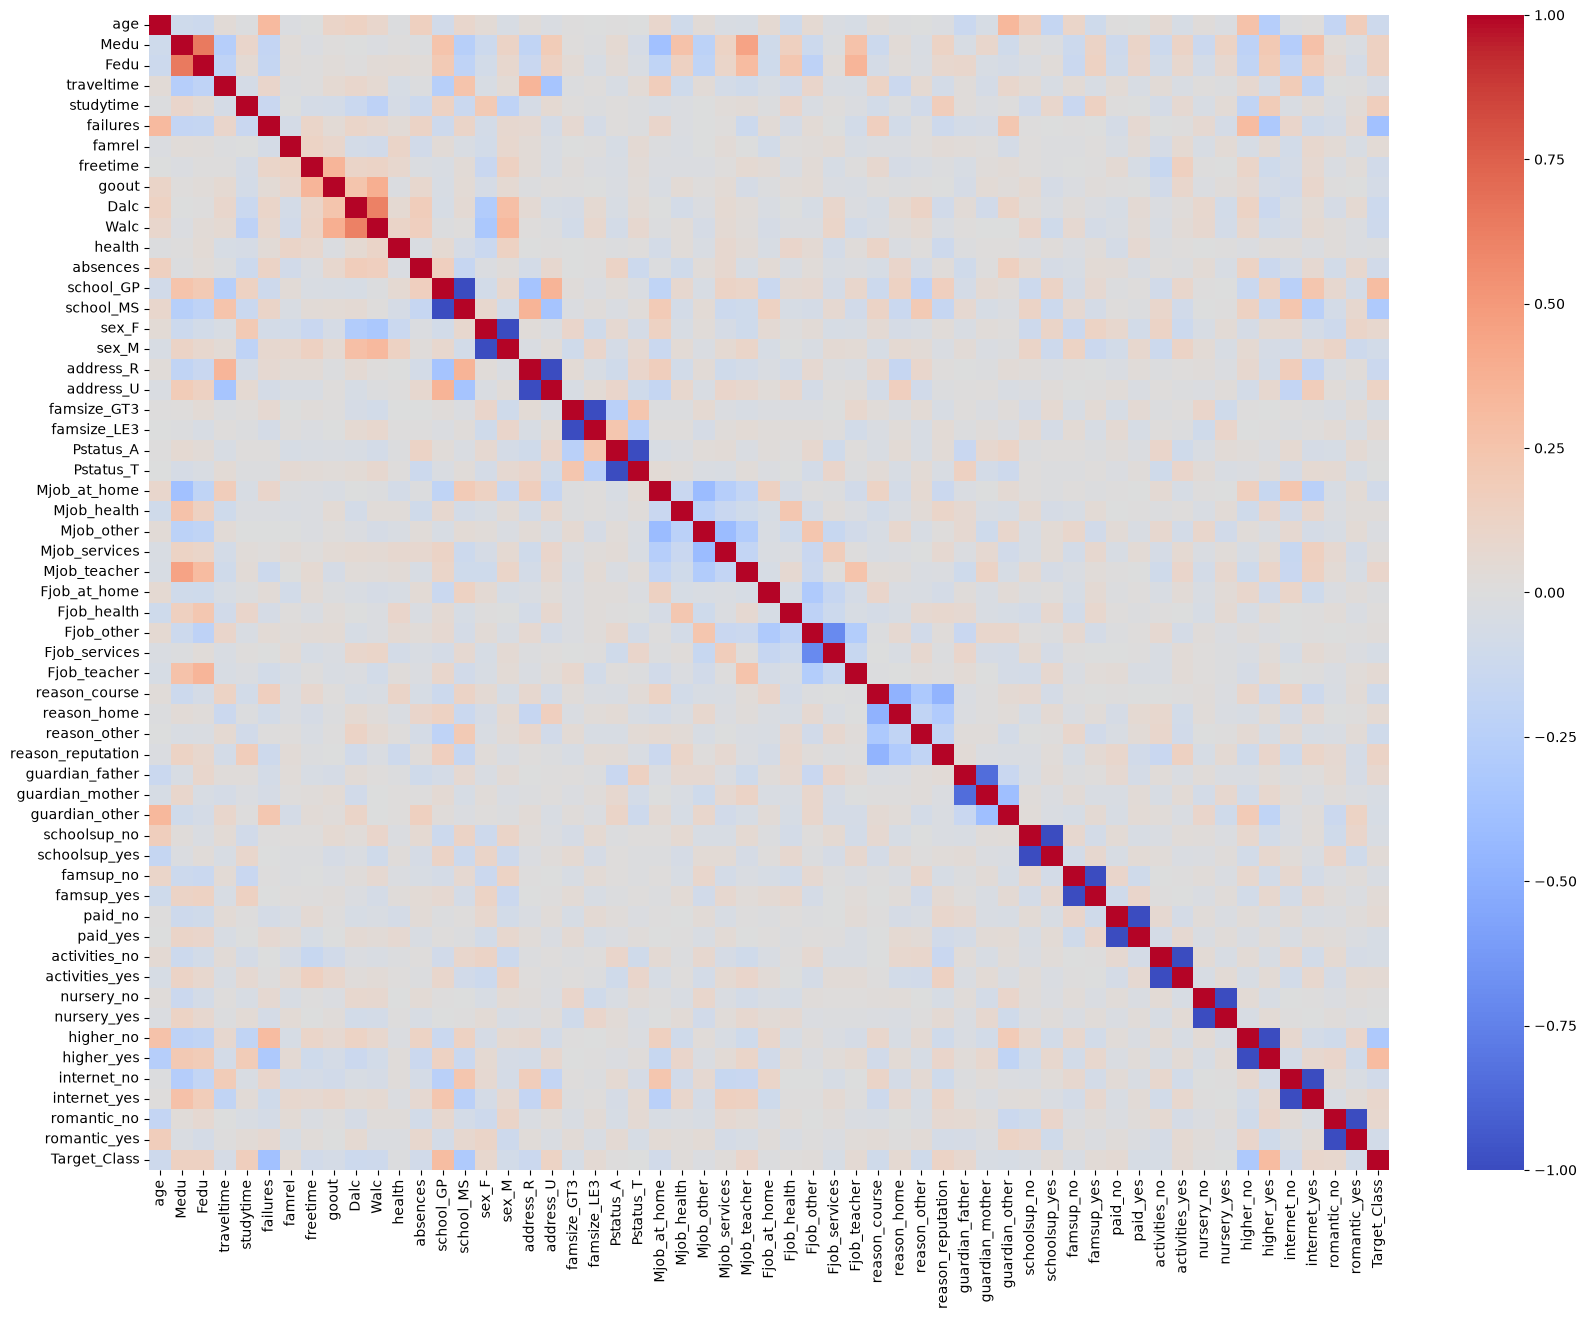

In [65]:
# 8) Check the dependences between each of the independent variable and the target variable and among
# the independent variables. Output correlation table and corresponding heatmap results.

corr_data = X_encoded.copy()
corr_data['Target_Class'] = Y_encoded

corr_table = corr_data.corr()
print(corr_table)
plt.figure(figsize=(20, 15))
sns.heatmap(corr_table, annot=False, cmap='coolwarm')
plt.show()